# E11 · Two-branch network: EfficientNet-B0 + MobileNetV3-Small in one model

One network for the **≤ 10M track** that contains both trained models as branches behind **one input layer**:

```
image (12 bands)
   │
one Conv2d(12 → 48, 3×3, stride 2)                         ← the only layer that sees the image
   ├─ channels 0–31  → EfficientNet-B0 blocks   → 1280 features ─┐
   └─ channels 32–47 → MobileNetV3-Small blocks →  576 features ─┴─ concat → Dropout → Linear(1856, 10)
```

| Variant | Start | Parameters |
|---|---|---|
| E09a (medium track) | EfficientNet-B0 | 4.02M |
| E10a (small track) | MobileNetV3-Small | 0.93M |
| **E11a** | both, trained weights of E09a and E10a, then fine-tuned together | 4.96M |

**Start = average of the two models.** The input convolution gets E09a's 32 and E10a's 16 first-layer filters (both
were 3×3, stride 2), each branch its trained blocks, and the classifier half of each model's head. Before training the
network therefore outputs exactly the mean of the two models' logits. Fine-tuning then trains the whole network with
the E09a data (EuroSAT + round-3 pseudo-labels from teacher `E06c`): the classifier can learn which branch to trust
for which class, and both branches adapt to each other. It is one model with one weights file, not an ensemble.

**Training:** 10 epochs at learning rate 3e-4 (fine-tuning, not from ImageNet). `LOAD_RUNS` points to the saved run;
`None` = train again (about 15–20 minutes on an M4 GPU).

## 1 · Setup and data

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, class_mix, compare_variants, find_run, finish_run, kaggle_monitor,
                            kaggle_score, load_experiment_data, load_saved_model, plot_class_mix,
                            plot_variant_curves, select_view_agree, teacher_predictions, view_agreement)
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import Normalizer, TrainConfig, fit, load_run, predict_views
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E11_two_branch"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E11a": "runs/2026-10-25_0017_pl_r3_view_agree_contrast_aug_hist_split_two_branch",
}
TEACHER = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN, 71.50%
CAPS = {"SeaLake": 400}        # random subset of the agreeing images; other classes: all
REPEAT = 2                     # Kaggle images per epoch, as in E06c
REFERENCE = "adabn_balanced_pl_r3_view_agree_contrast_aug_hist_split_effb0"   # E09a + AdaBN, 71.78% (medium track)
BIG_RUN = "pl_r3_view_agree_contrast_aug_hist_split_effb0"      # E09a, trained weights (no AdaBN)
SMALL_RUN = "pl_r3_view_agree_contrast_aug_hist_split_mnv3s"    # E10a, trained weights (no AdaBN), 70.94%
MODEL = "two_branch_effb0_mnv3s"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=10, batch_size=128, lr=3e-4, weight_decay=1e-4,
                  label_smoothing=0.1, patience=4, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # augmentation as in E09a
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
results = {}                        # variant -> RunResult, compared at the end

data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())


def train_or_load(variant, tr_images, tr_labels):
    """Fine-tune from E09a + E10a on EuroSAT + pseudo-labels, or load the saved run."""
    if LOAD_RUNS[variant]:
        model, normalizer, history = load_saved_model(LOAD_RUNS[variant], device)
        return model, normalizer, history, None
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    model = build_model(MODEL, bands=BANDS, pretrained=False).to(device)
    big, big_norm, _ = load_run(find_run(BIG_RUN), device)
    small, small_norm, _ = load_run(find_run(SMALL_RUN), device)
    assert big_norm.mean == normalizer.mean == small_norm.mean, "branches were trained with other input statistics"
    model.init_from(big, small)
    del big, small
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))
    return model, normalizer, history, best_state


def base_config(variant, run_name, description, pseudo_labels):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg),
            "split": "split_seed42", "pseudo_labels": pseudo_labels,
            "init": {"big": BIG_RUN, "small": SMALL_RUN}}

Device: Apple GPU (MPS)


train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 2 · Pseudo-labels (as in E09a)

`E06c` + AdaBN labels every Kaggle image (8 views averaged); all images whose 8 views agree are kept, SeaLake cut to
a random `CAPS`. Same seed and selection as E09a.

In [2]:
table, teacher_prob = teacher_predictions(TEACHER, data, device)
hard_idx = select_view_agree(table, CAPS, SEED)
print(f"{len(hard_idx):,} pseudo-labelled Kaggle images (E09a: 2,948)")
table.loc[hard_idx, "pred"].value_counts().reindex(CLASSES).to_frame("pseudo-labels")

2,948 pseudo-labelled Kaggle images (E09a: 2,948)


,pseudo-labels
pred,
AnnualCrop,300
Forest,362
HerbaceousVegetation,311
Highway,297
Industrial,224
Pasture,216
PermanentCrop,270
Residential,341
River,227


## 3 · E11a · Two-branch network, fine-tuned

The parameter count is checked against `MEDIUM_TRACK_LIMIT` (10M) in `finish_run`.

In [3]:
tr_images, tr_labels, _ = add_pseudo_labels(data, table, hard_idx, repeat=REPEAT)
model, normalizer, history, best_state = train_or_load("E11a", tr_images, tr_labels)
results["E11a"] = finish_run(model, normalizer, history, best_state, data, variant="E11a", load_run=LOAD_RUNS["E11a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E11a", "pl_r3_view_agree_contrast_aug_hist_split_two_branch",
                       "Two-branch EfficientNet-B0 + MobileNetV3-Small, one input layer, init from E09a + E10a, fine-tuned 10 epochs; E09a data",
                       {"teacher": TEACHER, "selection": "view_agree", "caps": CAPS, "repeat": REPEAT,
                        "n_images": int(len(hard_idx))}))
del tr_images, tr_labels

Pseudo-labelled Kaggle images: 2,948 of 4,232, used 2x (23.8% of the training set, 24,796 images)


epoch  1  train loss 0.511 acc 0.997  val loss 0.134 acc 0.983 *  val_conf 0.910  kg_conf 0.891  kg_sealake 0.241  kg_share_AnnualCrop 0.097  kg_share_Forest 0.108  kg_share_HerbaceousVegetation 0.095  kg_share_Highway 0.086  kg_share_Industrial 0.060  kg_share_Pasture 0.069  kg_share_PermanentCrop 0.086  kg_share_Residential 0.096  kg_share_River 0.060  kg_share_SeaLake 0.241  (80s)


epoch  2  train loss 0.521 acc 0.994  val loss 0.146 acc 0.982    val_conf 0.897  kg_conf 0.872  kg_sealake 0.241  kg_share_AnnualCrop 0.097  kg_share_Forest 0.107  kg_share_HerbaceousVegetation 0.099  kg_share_Highway 0.080  kg_share_Industrial 0.058  kg_share_Pasture 0.068  kg_share_PermanentCrop 0.093  kg_share_Residential 0.097  kg_share_River 0.060  kg_share_SeaLake 0.241  (78s)


epoch  3  train loss 0.518 acc 0.995  val loss 0.140 acc 0.983 *  val_conf 0.899  kg_conf 0.875  kg_sealake 0.242  kg_share_AnnualCrop 0.089  kg_share_Forest 0.107  kg_share_HerbaceousVegetation 0.103  kg_share_Highway 0.081  kg_share_Industrial 0.060  kg_share_Pasture 0.073  kg_share_PermanentCrop 0.093  kg_share_Residential 0.095  kg_share_River 0.057  kg_share_SeaLake 0.242  (83s)


epoch  4  train loss 0.517 acc 0.995  val loss 0.134 acc 0.984 *  val_conf 0.905  kg_conf 0.879  kg_sealake 0.241  kg_share_AnnualCrop 0.095  kg_share_Forest 0.095  kg_share_HerbaceousVegetation 0.116  kg_share_Highway 0.079  kg_share_Industrial 0.065  kg_share_Pasture 0.071  kg_share_PermanentCrop 0.088  kg_share_Residential 0.092  kg_share_River 0.058  kg_share_SeaLake 0.241  (117s)


...

epoch  7  train loss 0.510 acc 0.998  val loss 0.134 acc 0.984    val_conf 0.902  kg_conf 0.880  kg_sealake 0.241  kg_share_AnnualCrop 0.086  kg_share_Forest 0.105  kg_share_HerbaceousVegetation 0.103  kg_share_Highway 0.081  kg_share_Industrial 0.061  kg_share_Pasture 0.072  kg_share_PermanentCrop 0.096  kg_share_Residential 0.095  kg_share_River 0.058  kg_share_SeaLake 0.241  (88s)


epoch  8  train loss 0.507 acc 0.999  val loss 0.132 acc 0.985 *  val_conf 0.902  kg_conf 0.880  kg_sealake 0.241  kg_share_AnnualCrop 0.085  kg_share_Forest 0.107  kg_share_HerbaceousVegetation 0.103  kg_share_Highway 0.083  kg_share_Industrial 0.060  kg_share_Pasture 0.072  kg_share_PermanentCrop 0.098  kg_share_Residential 0.093  kg_share_River 0.059  kg_share_SeaLake 0.241  (90s)


epoch  9  train loss 0.507 acc 0.999  val loss 0.134 acc 0.986 *  val_conf 0.901  kg_conf 0.879  kg_sealake 0.241  kg_share_AnnualCrop 0.087  kg_share_Forest 0.110  kg_share_HerbaceousVegetation 0.099  kg_share_Highway 0.084  kg_share_Industrial 0.061  kg_share_Pasture 0.072  kg_share_PermanentCrop 0.093  kg_share_Residential 0.095  kg_share_River 0.058  kg_share_SeaLake 0.241  (89s)


epoch 10  train loss 0.506 acc 0.999  val loss 0.131 acc 0.988 *  val_conf 0.902  kg_conf 0.879  kg_sealake 0.242  kg_share_AnnualCrop 0.085  kg_share_Forest 0.108  kg_share_HerbaceousVegetation 0.099  kg_share_Highway 0.083  kg_share_Industrial 0.064  kg_share_Pasture 0.069  kg_share_PermanentCrop 0.097  kg_share_Residential 0.095  kg_share_River 0.058  kg_share_SeaLake 0.242  (87s)


E11a: internal test 98.72% · Kaggle confidence 87.0% (with AdaBN 83.6%) · 4,957,014 parameters
  run folders: runs/2026-10-25_0017_pl_r3_view_agree_contrast_aug_hist_split_two_branch, runs/2026-10-25_0018_adabn_balanced_pl_r3_view_agree_contrast_aug_hist_split_two_branch


## 4 · Comparison with E09a, E10a and their plain average

`E09a + E10a (average)` is the starting point of E11a (the network before fine-tuning): it shows what joint training
adds on top of simply combining the two models.

In [4]:
ref_dir = find_run(REFERENCE)
r_model, r_norm, _ = load_run(ref_dir, device)
ref_views = predict_views(r_model, data.kg_images, r_norm)
ref_prob = ref_views.mean(0)

def kaggle_views(model, norm):
    return predict_views(model, data.kg_images, norm)


small_model, small_norm, _ = load_run(find_run(SMALL_RUN), device)
small_prob = kaggle_views(small_model, small_norm).mean(0)
start = build_model(MODEL, bands=BANDS, pretrained=False).to(device)
start.init_from(load_run(find_run(BIG_RUN), device)[0], small_model)
start_views = kaggle_views(start.eval(), small_norm)
summary = compare_variants(results, reference=ref_prob, reference_name="E09a")
r_metrics = json.loads((find_run(REFERENCE.removeprefix("adabn_balanced_")) / "metrics.json").read_text())
summary.loc["E09a (medium track)"] = {"description": "EfficientNet-B0, 4.02M", "internal test (%)": r_metrics["internal_test_acc"] * 100,
                                      "confidence (%)": ref_prob.max(1).mean() * 100,
                                      "view agreement (%)": view_agreement(ref_views) * 100,
                                      "same class as E09a (%)": 100.0, "Kaggle public (%)": kaggle_score(ref_dir)}
summary.loc["E10a (small track)"] = {"description": "MobileNetV3-Small, 0.93M, no AdaBN",
                                     "confidence (%)": small_prob.max(1).mean() * 100,
                                     "same class as E09a (%)": (small_prob.argmax(1) == ref_prob.argmax(1)).mean() * 100,
                                     "Kaggle public (%)": kaggle_score(find_run(SMALL_RUN))}
summary.loc["E09a + E10a (average)"] = {"description": "E11a before fine-tuning",
                                        "confidence (%)": start_views.mean(0).max(1).mean() * 100,
                                        "view agreement (%)": view_agreement(start_views) * 100,
                                        "same class as E09a (%)": (start_views.mean(0).argmax(1) == ref_prob.argmax(1)).mean() * 100}
for k, r in results.items():
    changed = r.prob_ada.argmax(1) != ref_prob.argmax(1)
    summary.loc[k, "differs: teacher unsure (%)"] = changed[table["conf"].values < 0.6].mean() * 100
    summary.loc[k, "differs: teacher confident (%)"] = changed[table["conf"].values >= 0.6].mean() * 100
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E09a (%),Kaggle public (%),differs: teacher unsure (%),differs: teacher confident (%)
E11a,Two-branch EfficientNet-B0 + MobileNetV3-Small...,98.716049,83.562698,89.603025,97.21172,None,21.95,0.5
E09a (medium track),"EfficientNet-B0, 4.02M",98.864198,85.016815,88.657845,100.0,71.782,NaN,NaN
E10a (small track),"MobileNetV3-Small, 0.93M, no AdaBN",NaN,86.581909,NaN,93.029301,70.94,NaN,NaN
E09a + E10a (average),E11a before fine-tuning,NaN,86.708054,91.776938,95.81758,NaN,NaN,NaN


In [5]:
# Different predictions: E09a's class (rows) -> E11a's class (columns)
ref_pred = np.array(CLASSES)[ref_prob.argmax(1)]
for k, r in results.items():
    new = np.array(CLASSES)[r.prob_ada.argmax(1)]
    changed = new != ref_pred
    print(f"{k}: {changed.sum()} images differ from E09a ({changed.mean():.1%})")
    display(pd.crosstab(ref_pred[changed], new[changed]).rename_axis(index="E09a", columns=k))

E11a: 118 images differ from E09a (2.8%)


E11a,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
E09a,,,,,,,,,,
AnnualCrop,0,0,0,2,0,3,11,1,1,0
Forest,0,0,8,1,0,4,0,0,0,0
HerbaceousVegetation,0,3,0,2,1,1,1,1,0,0
Highway,0,0,2,0,2,0,2,1,0,0
Industrial,0,0,1,3,0,1,1,5,0,0
Pasture,0,2,1,1,1,0,5,1,1,0
PermanentCrop,3,0,4,2,2,9,0,2,2,0
Residential,0,1,2,3,6,0,1,0,2,0
River,2,0,2,0,0,0,1,1,0,2


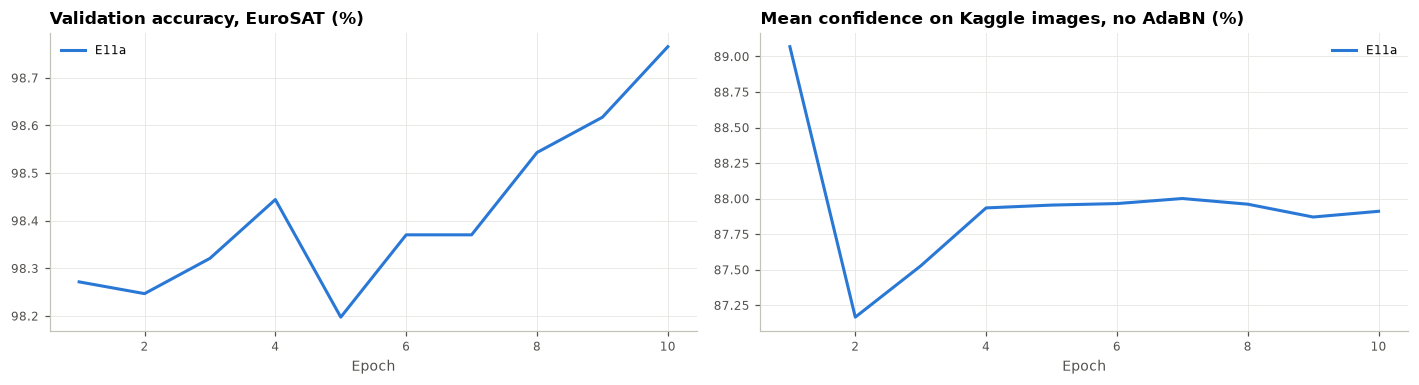

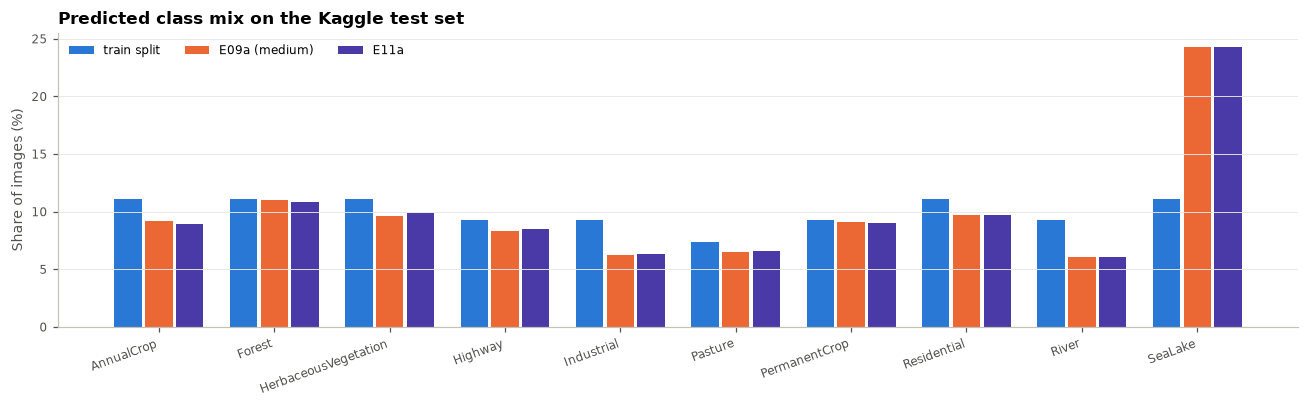

In [6]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "E09a (medium)": class_mix(ref_prob),
                             **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 5 · Conclusion

| Model | Parameters | Internal test | Kaggle confidence | View agreement | Same class as E09a | Kaggle public |
|---|---|---|---|---|---|---|
| **E09a, no AdaBN** | **4.02M** | 98.86% | 87.4% | – | – | **72.67% (best)** |
| E09a + AdaBN | 4.02M | 98.86% | 85.0% | 88.7% | – | 71.78% |
| E10a (no AdaBN) | 0.93M | 98.02% | 86.6% | – | 93.0% | 70.94% |
| E09a + E10a average (E11a at start) | 4.96M | – | 86.7% | 91.8% | 95.8% | not saved |
| E11a + AdaBN | 4.96M | 98.72% | 83.6% | 89.6% | 97.2% | 71.27% |
| E11a, no AdaBN | 4.96M | 98.72% | 87.0% | – | – | 71.92% |

- **The network works as one model** with one input layer, 4.96M parameters, and trains at ~85 s per epoch (19 minutes in total).
- **Fine-tuning has little to learn.** Both branches were already trained on exactly this data: training accuracy is
  99.7% from the first epoch and the loss sits at the label-smoothing floor (~0.51). Validation accuracy rises only
  from 98.3% to 98.8%; internal test 98.72% is slightly *below* E09a alone (98.86%).
- **The network falls back to the EfficientNet branch.** The plain average differs from E09a on 4.2% of the Kaggle
  images; after fine-tuning only 2.8% (118 images), mostly the crop pairs (AnnualCrop → PermanentCrop, PermanentCrop →
  Pasture). The classifier learns to trust the branch that fits the training data best, which is not necessarily the
  one that is better on Kaggle.
- **Kaggle: 71.92% without AdaBN, 71.27% with.** At first this looked like a small gain over E09a (71.78%), but that
  compared *without* against *with* AdaBN. **E09a without AdaBN scores 72.67%** (submitted 2026-10-25), so the second
  branch costs 0.75 points: the fine-tuned network is worse than its EfficientNet branch alone.
- **AdaBN hurts the models trained on E09a's pseudo-labels** (E09a −0.89, E10a −0.33, E11a −0.65), but still helped
  E06c (+0.42, checked 2026-10-25) and E04 (+3.8). The more pseudo-labelled Kaggle images in training (E06c 2,314,
  E09a 2,948 incl. 400 SeaLake), the more BatchNorm already carries Kaggle statistics and the less AdaBN has to fix.

**Next:** For joint training to add something, the branches need a signal they have
not fitted yet (e.g. new pseudo-labels from E11a itself, a round 4) instead of the same data again.
